In [ ]:
import numpy as np
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
iris=load_iris()
data=iris.data
target=iris.target
feature_names=iris.feature_names
print("Feature Name:")
print(feature_names)
print("\nOriginal Data Shape:")
print(data.shape)
print("\nFirst 5 Rows:")
print(data[:5])


Feature Name:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Original Data Shape:
(150, 4)

First 5 Rows:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


In [ ]:
def mean_center(data):
    mean_vals=np.mean(data,axis=0)
    centered_data=data-mean_vals
    return centered_data,mean_vals
def calculate_covariance(data):
    n=data.shape[0]
    covariance_matrix=np.dot(data.T,data)/(n-1)
    return covariance_matrix
def perform_pca(data,num_components):
    centered_data,mean_vals=mean_center(data)
    covariance_matrix=calculate_covariance(centered_data)
    eigenvalues,eigenvectors=np.linalg.eigh(covariance_matrix)
    indices=np.argsort(eigenvalues)[::-1]
    eigenvalues=eigenvalues[indices]
    eigenvectors=eigenvectors[:,indices]
    selected_eigenvectors=eigenvectors[:, :num_components]
    pca_result=np.dot(centered_data,selected_eigenvectors)
    return(pca_result,eigenvalues,selected_eigenvectors,mean_vals,covariance_matrix)
num_components=2
(pca_result,eigenvalues,eigenvectors,mean_vals,covariance_matrix)=perform_pca(data,num_components)
print("\n" + "-" * 50)
print("PCA RESULTS")
print("-" * 50)
print("\nMean Values:")
print(mean_vals)

print("\nCovariance Matrix:")
print(covariance_matrix)

print("\nEigenvalues:")
print(eigenvalues)

print("\nSelected Eigenvectors:")
print(eigenvectors)

print("\nReduced Data Shape:")
print(pca_result.shape)

print("\nFirst 5 Rows of PCA Result:")
print(pca_result[:5])



--------------------------------------------------
PCA RESULTS
--------------------------------------------------

Mean Values:
[5.84333333 3.05733333 3.758      1.19933333]

Covariance Matrix:
[[ 0.68569351 -0.042434    1.27431544  0.51627069]
 [-0.042434    0.18997942 -0.32965638 -0.12163937]
 [ 1.27431544 -0.32965638  3.11627785  1.2956094 ]
 [ 0.51627069 -0.12163937  1.2956094   0.58100626]]

Eigenvalues:
[4.22824171 0.24267075 0.0782095  0.02383509]

Selected Eigenvectors:
[[-0.36138659  0.65658877]
 [ 0.08452251  0.73016143]
 [-0.85667061 -0.17337266]
 [-0.3582892  -0.07548102]]

Reduced Data Shape:
(150, 2)

First 5 Rows of PCA Result:
[[ 2.68412563  0.31939725]
 [ 2.71414169 -0.17700123]
 [ 2.88899057 -0.14494943]
 [ 2.74534286 -0.31829898]
 [ 2.72871654  0.32675451]]



EXPLAINED VARIANCE
PC1: 92.46%
PC2: 5.31%
PC3: 1.71%
PC4: 0.52%

Cumulative Explained Variance:
First 1 PC(s): 92.46%
First 2 PC(s): 97.77%
First 3 PC(s): 99.48%
First 4 PC(s): 100.00%


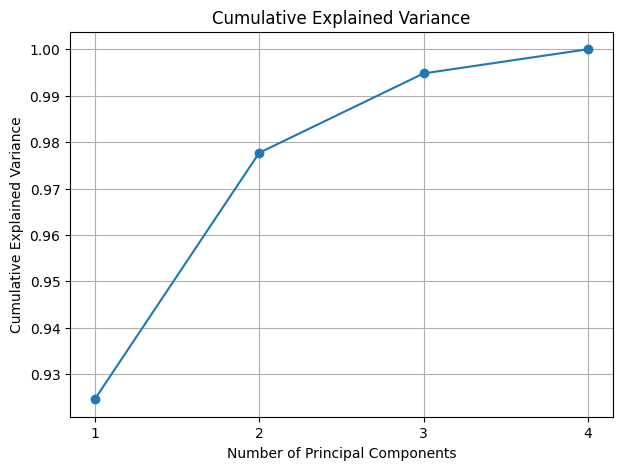

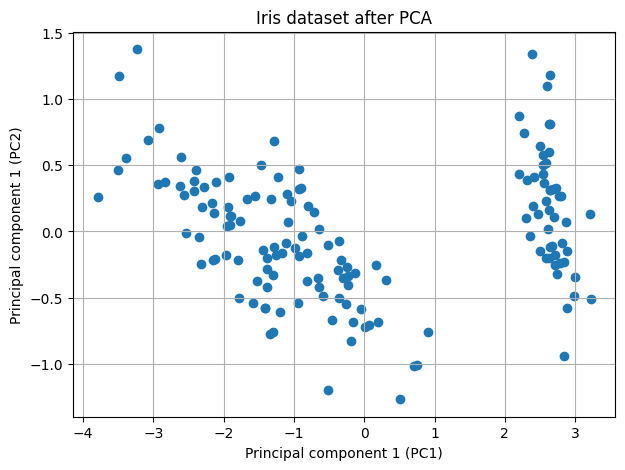

In [ ]:
explained_variance_ratio = (eigenvalues / np.sum(eigenvalues))

cumulative_variance = np.cumsum(explained_variance_ratio)

print("\n" + "=" * 50)
print("EXPLAINED VARIANCE")
print("=" * 50)

for i, value in enumerate(explained_variance_ratio):
    print(f"PC{i + 1}: {value * 100:.2f}%")

print("\nCumulative Explained Variance:")

for i, value in enumerate(cumulative_variance):
    print(
        f"First {i + 1} PC(s): "
        f"{value * 100:.2f}%"
    )

plt.figure(figsize=(7, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.xticks(range(1, len(cumulative_variance) + 1))

plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1]
)
plt.title("Iris dataset after PCA")
plt.xlabel("Principal component 1 (PC1)")
plt.ylabel("Principal component 1 (PC2)")
plt.grid(True)
plt.show()



Original 2D data shape: (9, 2)
Original 2D data:
 [[1.  1. ]
 [2.  2.5]
 [3.  3.2]
 [4.  4.5]
 [5.  5.1]
 [6.  6.5]
 [7.  7.8]
 [8.  8.1]
 [9.  9.5]]

Reduced 1D data shape: (9, 1)
Reduced 1D data:
 [[-5.91189391]
 [-4.13792511]
 [-2.93994721]
 [-1.30997613]
 [-0.18399709]
 [ 1.51797285]
 [ 3.14794392]
 [ 4.05792638]
 [ 5.75989631]]

Explained variance ratio: [0.99807998]
Cumulative explained variance: 0.9980799808522799

Principal component (eigenvector):
 [[0.69398587 0.71998862]]


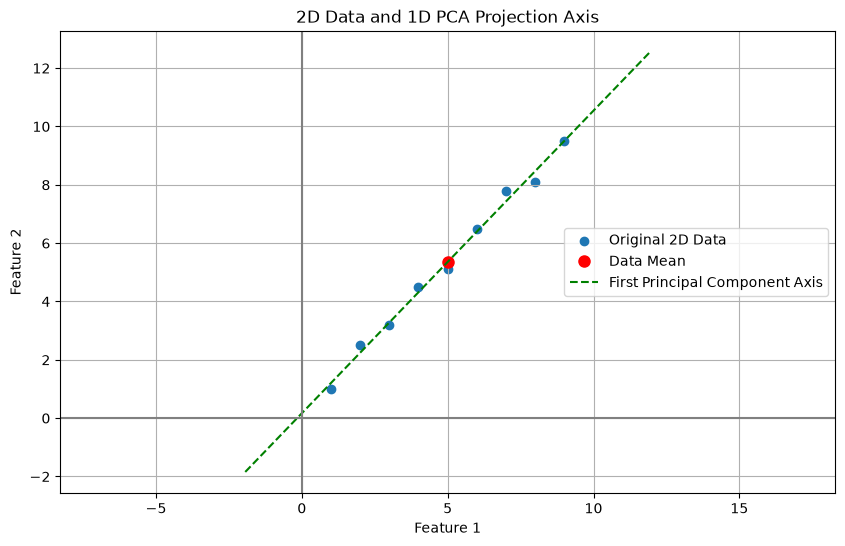


Green dashed line represents the first principal component.


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Input Data
X = np.array([
    [1, 1], [2, 2.5], [3, 3.2],
    [4, 4.5], [5, 5.1], [6, 6.5],
    [7, 7.8], [8, 8.1], [9, 9.5]
])

print("Original 2D data shape:", X.shape)
print("Original 2D data:\n", X)

# Apply PCA
pca = PCA(n_components=1)
X_reduced = pca.fit_transform(X)

print("\nReduced 1D data shape:", X_reduced.shape)
print("Reduced 1D data:\n", X_reduced)

print("\nExplained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative explained variance:", np.sum(pca.explained_variance_ratio_))
print("\nPrincipal component (eigenvector):\n", pca.components_)

# Plot Original Data and PCA Axis
mean = np.mean(X, axis=0)
v = pca.components_[0]
scale = 10

plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], label='Original 2D Data')
plt.plot(mean[0], mean[1], 'ro', markersize=8, label='Data Mean')

plt.plot(
    [mean[0]-v[0]*scale, mean[0]+v[0]*scale],
    [mean[1]-v[1]*scale, mean[1]+v[1]*scale],
    'g--', label='First Principal Component Axis'
)

plt.title('2D Data and 1D PCA Projection Axis')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.axhline(0,color='gray')
plt.axvline(0,color='gray')
plt.grid(True)
plt.legend()
plt.axis('equal')
plt.show()

print("\nGreen dashed line represents the first principal component.")